# Phase 2: WHO Surveillance & Epidemiological Indicators
Run `01_clean_data.ipynb` first. This notebook reads `outputs/cleaned_train.csv`.

The WHO measles indicators are calculated on the **suspected measles cases** (`Disease/Condition == "Measles"`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

date_columns = ["Reporting Date", "Date of Onset/Emergence", "Date of Detection/Seen",
                "Date Specimen Collected", "Date Specimen Sent",
                "Date Specimen Received at Lab", "Date Lab Tested/ Reviewed"]

train = pd.read_csv("outputs/cleaned_train.csv", parse_dates=date_columns)
measles = train[train["Disease/Condition"] == "Measles"].copy()
POPULATION = 5_000_000

print("All records:", train.shape[0], " | Measles cases:", measles.shape[0])

All records: 4107  | Measles cases: 3295


## 1. Time between two steps
Subtracting two date columns gives a time difference; `.dt.days` turns it into a number of days (class notes: *Working with dates*).

In [2]:
measles["Days report to investigation"] = (measles["Date of Detection/Seen"] - measles["Reporting Date"]).dt.days
measles["Days sent to received"] = (measles["Date Specimen Received at Lab"] - measles["Date Specimen Sent"]).dt.days
measles["Days received to tested"] = (measles["Date Lab Tested/ Reviewed"] - measles["Date Specimen Received at Lab"]).dt.days
measles["Days onset to collection"] = (measles["Date Specimen Collected"] - measles["Date of Onset/Emergence"]).dt.days

measles[["Days report to investigation", "Days sent to received",
         "Days received to tested", "Days onset to collection"]].describe()

,Days report to investigation,Days sent to received,Days received to tested,Days onset to collection
count,3288.000000,127.000000,22.000000,657.000000
mean,-1.718066,0.291339,2.090909,2.656012
std,26.979534,0.827218,1.849301,49.746557
min,-370.000000,-3.000000,0.000000,-363.000000
25%,-1.000000,0.000000,1.000000,2.000000
50%,0.000000,0.000000,1.500000,3.000000
75%,0.000000,0.000000,3.000000,5.000000
max,366.000000,5.000000,7.000000,369.000000


A function for the timeliness indicators:
* **eligible** = both dates present and the gap is not negative (negative = date-sequence error, excluded)
* **on time** = eligible and gap ≤ target

In [3]:
def timeliness(days_column, max_days):
    days = measles[days_column]
    eligible = days.notna() & (days >= 0)
    on_time = eligible & (days <= max_days)
    percent = on_time.sum() / eligible.sum() * 100
    return round(percent, 1), on_time.sum(), eligible.sum()

## 2. WHO performance indicators

In [16]:
# (a) Timeliness of case investigation: detection - reporting <= 2 days
investigation = timeliness("Days report to investigation", 2)

# (b) Timeliness of specimen transport: received - sent <= 3 days
transport = timeliness("Days sent to received", 3)

# (c) Timeliness of lab results: tested - received <= 7 days
lab = timeliness("Days received to tested", 7)

# (d) Adequate specimens: collected - onset <= 28 days
adequate = timeliness("Days onset to collection", 28)
adequate_all_cases = round(adequate[1] / measles.shape[0] * 100, 1)   # no specimen = not adequate

print("Timeliness of investigation:", investigation)
print("Timeliness of transport:", transport)
print("Timeliness of lab results:", lab)
print("Adequate specimens (of specimens):", adequate)
print("Adequate specimens (of all cases):", adequate_all_cases)

Timeliness of investigation: (np.float64(97.8), np.int64(2251), np.int64(2302))
Timeliness of transport: (np.float64(98.4), np.int64(123), np.int64(125))
Timeliness of lab results: (np.float64(100.0), np.int64(22), np.int64(22))
Adequate specimens (of specimens): (np.float64(98.5), np.int64(637), np.int64(647))
Adequate specimens (of all cases): 19.3


In [17]:
# (e) Completeness: Age, Sex, District of Residence, Vaccination Status and Final classification all filled in
complete = (
    measles["Age in Years"].notna()
    & measles["Patient Sex"].notna()
    & measles["District of Residence"].notna()
    & (measles["Vaccination Status"] != "Unknown")
    & (measles["Final Epi-classification (std)"] != "Missing")
)
completeness = round(complete.mean() * 100, 1)
print(f"Completeness: {completeness}%  ({complete.sum()} of {measles.shape[0]} forms)")

Completeness: 86.0%  (2833 of 3295 forms)


In [18]:
# (f) NMNR discarded rate per 100,000 population
discarded = (measles["Final Epi-classification (std)"] == "Discarded") | (measles["Final Laboratory Result (std)"] == "Negative")
weeks_covered = measles["Epi week"].nunique()

nmnr_rate = discarded.sum() / POPULATION * 100000
nmnr_annual = nmnr_rate * 52 / weeks_covered      # the WHO target is per YEAR

print(f"Discarded cases: {discarded.sum()} in {weeks_covered} epi weeks")
print(f"NMNR rate: {nmnr_rate:.2f} per 100,000 (period)  ->  {nmnr_annual:.2f} per 100,000 per year")

Discarded cases: 6 in 16 epi weeks
NMNR rate: 0.12 per 100,000 (period)  ->  0.39 per 100,000 per year


### Summary table: indicators vs WHO targets (Q2.2)

In [19]:
indicators = pd.DataFrame({
    "Indicator": ["NMNR discarded rate (per 100,000 / year)",
                  "Completeness of case investigation (%)",
                  "Timeliness of investigation <= 48h (%)",
                  "Timeliness of specimen transport <= 3 days (%)",
                  "Timeliness of lab results <= 7 days (%)",
                  "Adequate specimens <= 28 days (% of specimens)",
                  "Adequate specimens (% of all suspected cases)"],
    "Value": [round(nmnr_annual, 2), completeness, investigation[0], transport[0], lab[0], adequate[0], adequate_all_cases],
    "WHO target": [2, 80, 80, 80, 80, 80, 80],
    "Based on": [f"{discarded.sum()} discarded", f"{measles.shape[0]} cases", f"{investigation[2]} cases",
                 f"{transport[2]} specimens", f"{lab[2]} specimens", f"{adequate[2]} specimens", f"{measles.shape[0]} cases"],
})
indicators["Target met?"] = indicators["Value"] >= indicators["WHO target"]
indicators["Target met?"] = indicators["Target met?"].map({True: "YES", False: "NO - underperforming"})
indicators.to_csv("outputs/phase2_who_indicators.csv", index=False)
indicators

,Indicator,Value,WHO target,Based on,Target met?
0,"NMNR discarded rate (per 100,000 / year)",0.39,2,6 discarded,NO - underperforming
1,Completeness of case investigation (%),86.00,80,3295 cases,YES
2,Timeliness of investigation <= 48h (%),97.80,80,2302 cases,YES
3,Timeliness of specimen transport <= 3 days (%),98.40,80,125 specimens,YES
4,Timeliness of lab results <= 7 days (%),100.00,80,22 specimens,YES
5,Adequate specimens <= 28 days (% of specimens),98.50,80,647 specimens,YES
6,Adequate specimens (% of all suspected cases),19.30,80,3295 cases,NO - underperforming


## 3. Epidemiological indicators (Q2.3)

In [20]:
# Case Fatality Ratio
deaths = (measles["Outcome"] == "Dead").sum()
cfr = deaths / measles.shape[0] * 100
print(f"CFR = {deaths} deaths / {measles.shape[0]} cases = {cfr:.2f}%")

CFR = 13 deaths / 3295 cases = 0.39%


In [21]:
# Cases by age group (proportion of all cases)
age_order = ["<1 year", "1-4 years", "5-9 years", "10-14 years", "15+ years"]
by_age = (measles["Age Group"].value_counts(normalize=True) * 100).round(1).reindex(age_order)
by_age

Age Group
<1 year        19.8
1-4 years      33.3
5-9 years      24.8
10-14 years     9.0
15+ years      13.1
Name: proportion, dtype: float64

In [22]:
# Cases by sex
(measles["Patient Sex"].value_counts(normalize=True) * 100).round(1)

Patient Sex
Male      51.5
Female    48.5
Name: proportion, dtype: float64

In [23]:
# Age group x sex
measles.groupby(["Age Group", "Patient Sex"]).size().unstack().reindex(age_order)

Patient Sex,Female,Male
Age Group,,
<1 year,306,347
1-4 years,522,573
5-9 years,404,412
10-14 years,151,145
15+ years,214,218


In [24]:
# Immunity gaps: % zero-dose and % not vaccinated in each age group
immunity = measles.groupby("Age Group").agg(
    cases=("Dose Group", "count"),
    zero_dose=("Dose Group", lambda s: (s == "Zero-Dose").mean() * 100),
    not_vaccinated=("Vaccination Status", lambda s: (s == "Not vaccinated").mean() * 100),
).reindex(age_order).round(1)
immunity

,cases,zero_dose,not_vaccinated
Age Group,,,
<1 year,653,58.3,45.0
1-4 years,1095,28.5,23.4
5-9 years,816,29.0,19.6
10-14 years,296,39.2,20.9
15+ years,433,42.3,22.6


In [25]:
# Final classification breakdown
classification = (measles["Final Epi-classification (std)"].value_counts(normalize=True) * 100).round(1)
classification

Final Epi-classification (std)
Clinically Compatible       74.3
Suspected/Pending/Other     17.1
Epidemiologically Linked     7.3
Missing                      0.8
Laboratory-Confirmed         0.5
Discarded                    0.2
Name: proportion, dtype: float64

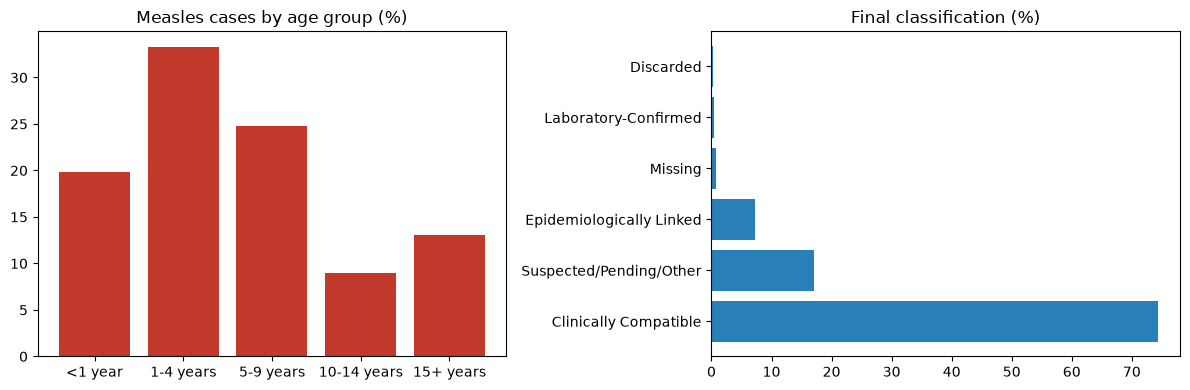

In [26]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(by_age.index, by_age.values, color="#c0392b")
plt.title("Measles cases by age group (%)")
plt.subplot(1, 2, 2)
plt.barh(classification.index, classification.values, color="#2980b9")
plt.title("Final classification (%)")
plt.tight_layout()
plt.show()

In [15]:
by_age.to_csv("outputs/phase2_cases_by_age.csv")
immunity.to_csv("outputs/phase2_immunity_gaps.csv")
classification.to_csv("outputs/phase2_classification.csv")
print("Saved Phase 2 tables to the outputs folder")

Saved Phase 2 tables to the outputs folder
